# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 5 Model evaluation and selection |
| Owner (name) | Chirchir Collins |
| Registration number | COM/0020/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [1]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "5"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [2]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

In [3]:

# Task 5: Check the shared dataset

import os

# Confirm the correct project folder
print("Current project folder:", os.getcwd())

# Check the classification dataset
print("Dataset found:",
      os.path.isfile("data/clean_credit.csv"))


Current project folder: /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04
Dataset found: True


## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [4]:

# Task 5: Load the prepared Credit Risk Dataset

DATA_FILE = "data/clean_credit.csv"

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Show the dataset dimensions
print("Dataset shape:", df.shape)

# Display the number of defaulted loans
print("\nLoan status counts:")
print(df["loan_status"].value_counts())

# Show the first five records
display(df.head())


Dataset shape: (32409, 25)

Loan status counts:
loan_status
0    25321
1     7088
Name: count, dtype: int64


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



## Task 5(a): Build a Machine Learning Pipeline

This section combines missing-value imputation, categorical encoding, numerical scaling and Logistic Regression into one pipeline. The preprocessing is fitted using training data only.


In [5]:

# Task 5(a): Build a classification pipeline

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Select the classification target
y = df["loan_status"].astype(int)

# Select original borrower and loan features
# Exclude loan_int_rate and rate_imputed
feature_columns = [
    "person_age",
    "person_income",
    "person_home_ownership",
    "person_emp_length",
    "loan_intent",
    "loan_grade",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length"
]

X = df[feature_columns].copy()

# Separate numerical and categorical columns
numeric_columns = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_grade",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length"
]

categorical_columns = [
    "person_home_ownership",
    "loan_intent"
]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing using ColumnTransformer
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Create the complete model pipeline
pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train the full pipeline
pipe.fit(X_train, y_train)

# Display results
print("PIPELINE CREATED SUCCESSFULLY!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Original input features:", X_train.shape[1])
print("Pipeline fitted:", hasattr(
    pipe.named_steps["classifier"], "coef_"
))

print("\nPipeline steps:")
print(list(pipe.named_steps.keys()))


PIPELINE CREATED SUCCESSFULLY!
Training records: 25927
Testing records: 6482
Original input features: 10
Pipeline fitted: True

Pipeline steps:
['preprocessing', 'classifier']



## Task 5(b): Five-Fold Cross-Validation

This section evaluates the classification pipeline using five-fold stratified cross-validation.

I use the F1-score to measure performance because the dataset contains fewer defaulted loans than non-defaulted loans.

Cross-validation helps determine whether the model performs consistently across different training and validation subsets.


In [6]:

# Task 5(b): Perform five-fold cross-validation

# Import cross-validation tools
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

# Create five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Run cross-validation on training data only
cv_scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

# Display the five F1-scores
print("FIVE-FOLD CROSS-VALIDATION RESULTS")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} F1-score: {score:.4f}")

# Calculate the mean and standard deviation
cv_mean = cv_scores.mean()
cv_std = cv_scores.std()

print("\nMean F1-score:", round(cv_mean, 4))
print("Standard deviation:", round(cv_std, 4))

print("\nCross-validation completed successfully!")


FIVE-FOLD CROSS-VALIDATION RESULTS
Fold 1 F1-score: 0.6196
Fold 2 F1-score: 0.6299
Fold 3 F1-score: 0.6123
Fold 4 F1-score: 0.6082
Fold 5 F1-score: 0.6107

Mean F1-score: 0.6161
Standard deviation: 0.0079

Cross-validation completed successfully!



## Task 5(c): Hyperparameter Tuning Using GridSearchCV

I use GridSearchCV with five-fold stratified cross-validation to find the best Logistic Regression settings. I tune C, which controls regularisation strength, and class_weight, which controls how the two loan classes are weighted.


In [7]:

# Task 5(c): Tune two Logistic Regression hyperparameters

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create reproducible five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the settings to compare
param_grid = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

# Build the hyperparameter search
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True
)

# Search using training data only
grid.fit(X_train, y_train)

# Keep the selected pipeline
best_pipeline = grid.best_estimator_

print("GRID SEARCH RESULTS")
print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

# Display all settings that were tested
grid_results = pd.DataFrame(grid.cv_results_)

display(
    grid_results[
        ["param_classifier__C",
         "param_classifier__class_weight",
         "mean_test_score"]
    ].round(4)
)

print("GridSearchCV completed successfully!")


GRID SEARCH RESULTS
Best parameters: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced'}
Best cross-validation F1: 0.6164


,param_classifier__C,param_classifier__class_weight,mean_test_score
0,0.1,None,0.6050
1,0.1,balanced,0.6155
2,1.0,None,0.6055
3,1.0,balanced,0.6161
4,10.0,None,0.6055
5,10.0,balanced,0.6164


GridSearchCV completed successfully!



## Task 5(d): Learning and Validation Curves

I use learning and validation curves to investigate how training size and model regularisation affect classification performance.


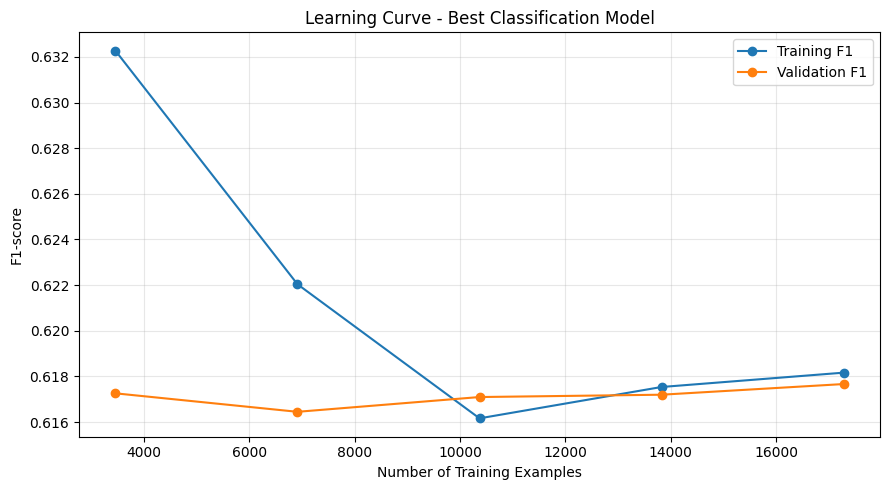

LEARNING CURVE RESULTS
Final training F1: 0.6182
Final validation F1: 0.6177
Final gap: 0.0005
Saved: outputs/learning_curve.png


In [8]:

# Task 5(d): Create the learning curve

from sklearn.model_selection import learning_curve, StratifiedKFold

cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluate learning at five training-set sizes
train_sizes, train_scores, validation_scores = learning_curve(
    best_pipeline,
    X_train,
    y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv3,
    scoring="f1",
    shuffle=True,
    random_state=42,
    n_jobs=1
)

# Calculate average scores
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

# Create the graph
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation F1"
)

plt.title("Learning Curve - Best Classification Model")
plt.xlabel("Number of Training Examples")
plt.ylabel("F1-score")

plt.legend()
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/learning_curve.png", dpi=150)
plt.show()

# Display results
print("LEARNING CURVE RESULTS")
print("Final training F1:", round(train_mean[-1], 4))
print("Final validation F1:", round(validation_mean[-1], 4))
print("Final gap:", round(
    train_mean[-1] - validation_mean[-1], 4
))

print("Saved: outputs/learning_curve.png")


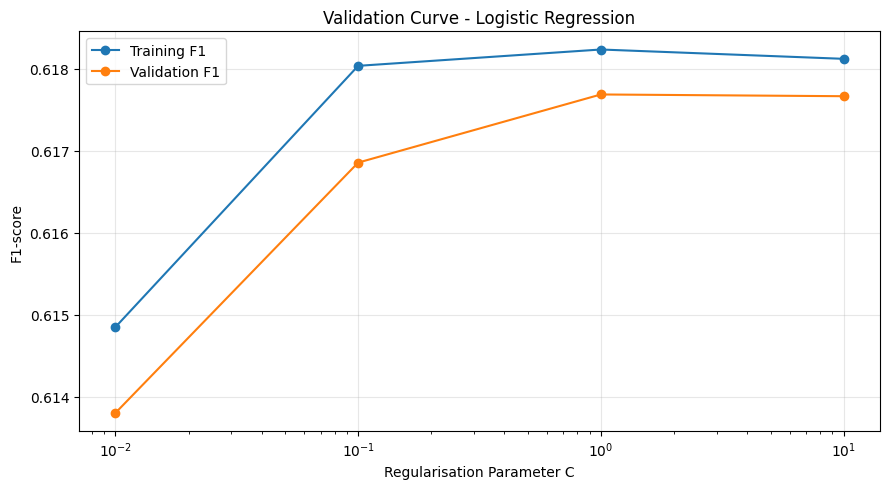

VALIDATION CURVE RESULTS


,C,Training F1,Validation F1
0,0.01,0.6148,0.6138
1,0.10,0.6180,0.6169
2,1.00,0.6182,0.6177
3,10.00,0.6181,0.6177


Saved: outputs/validation_curve.png


In [9]:

# Task 5(d): Create the validation curve

from sklearn.model_selection import validation_curve

# Regularisation values to investigate
c_values = [0.01, 0.1, 1.0, 10.0]

# Evaluate training and validation performance
val_train_scores, val_test_scores = validation_curve(
    best_pipeline,
    X_train,
    y_train,
    param_name="classifier__C",
    param_range=c_values,
    cv=cv3,
    scoring="f1",
    n_jobs=1
)

# Calculate mean scores
val_train_mean = val_train_scores.mean(axis=1)
val_test_mean = val_test_scores.mean(axis=1)

# Plot the validation curve
plt.figure(figsize=(9, 5))

plt.plot(
    c_values,
    val_train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    c_values,
    val_test_mean,
    marker="o",
    label="Validation F1"
)

plt.xscale("log")
plt.title("Validation Curve - Logistic Regression")
plt.xlabel("Regularisation Parameter C")
plt.ylabel("F1-score")

plt.legend()
plt.grid(alpha=0.3)

# Save the graph
plt.tight_layout()
plt.savefig("outputs/validation_curve.png", dpi=150)
plt.show()

# Display numerical results
validation_results = pd.DataFrame({
    "C": c_values,
    "Training F1": val_train_mean,
    "Validation F1": val_test_mean
})

print("VALIDATION CURVE RESULTS")
display(validation_results.round(4))

print("Saved: outputs/validation_curve.png")



## Task 5(e): Decision Threshold and Confusion Matrix

This section evaluates the selected model on the held-out test set, calculates precision and recall for loan defaults, and compares decision thresholds of 0.5 and 0.3.


In [10]:

# Task 5(e): Final evaluation and threshold comparison

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Obtain default probabilities from the best model
probabilities = best_pipeline.predict_proba(X_test)[:, 1]

# Compare the two required thresholds
threshold_rows = []

for threshold in [0.5, 0.3]:

    # Convert default probabilities into predictions
    predicted = (probabilities >= threshold).astype(int)

    # Get confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predicted,
        labels=[0, 1]
    ).ravel()

    # Store the scores and counts
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(
            y_test, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicted, zero_division=0
        ),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

# Store the required threshold results
threshold_results = pd.DataFrame(
    threshold_rows
).set_index("Threshold")

# Store the final test F1 at the default 0.5 threshold
test_score = float(
    threshold_results.loc[0.5, "F1"]
)

print("FINAL TEST RESULTS")
print("Best parameters:", grid.best_params_)
print("Final test F1:", round(test_score, 4))

print("\nTHRESHOLD COMPARISON")
display(threshold_results.round(4))

# Calculate precision and recall manually at 0.5
tp = int(threshold_results.loc[0.5, "TP"])
fp = int(threshold_results.loc[0.5, "FP"])
fn = int(threshold_results.loc[0.5, "FN"])

manual_precision = tp / (tp + fp)
manual_recall = tp / (tp + fn)

print("\nMANUAL CALCULATIONS AT THRESHOLD 0.5")
print(f"Precision = {tp} / ({tp} + {fp})")
print("Precision =", round(manual_precision, 4))

print(f"Recall = {tp} / ({tp} + {fn})")
print("Recall =", round(manual_recall, 4))

print("\nThreshold comparison completed!")


FINAL TEST RESULTS
Best parameters: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced'}
Final test F1: 0.6201

THRESHOLD COMPARISON


,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
Threshold,,,,,,,,
0.5,0.7896,0.5124,0.7849,0.6201,4005,1059,305,1113
0.3,0.6641,0.3850,0.8956,0.5385,3035,2029,148,1270



MANUAL CALCULATIONS AT THRESHOLD 0.5
Precision = 1113 / (1113 + 1059)
Precision = 0.5124
Recall = 1113 / (1113 + 305)
Recall = 0.7849

Threshold comparison completed!


### Task 5(e): Manual Precision and Recall Calculation

Using the confusion matrix at threshold 0.5:

- True Positives (TP) = 1113
- False Positives (FP) = 1059
- False Negatives (FN) = 305
- True Negatives (TN) = 4005

**Precision Calculation**

Precision = TP / (TP + FP)

Precision = 1113 / (1113 + 1059)

Precision = 1113 / 2172

**Precision = 0.5124 (51.24%)**

**Recall Calculation**

Recall = TP / (TP + FN)

Recall = 1113 / (1113 + 305)

Recall = 1113 / 1418

**Recall = 0.7849 (78.49%)**

**Threshold Comparison**

At threshold 0.5, the model correctly identified 1,113 defaulters and missed 305, with an F1-score of 0.6201.

At threshold 0.3, the model correctly identified 1,270 defaulters and missed only 148, but the F1-score decreased to 0.5385.

Reducing the threshold therefore identified 157 additional defaulters but incorrectly flagged 970 additional non-defaulters.

For a SACCO that prioritises detecting potential defaults, threshold 0.3 may be useful for initial screening, provided loan officers can handle the additional reviews. The final threshold should be selected using validation data and the financial costs of both types of errors.


### Task 5(e): Manual Precision and Recall Calculation

Using the confusion matrix at threshold 0.5:

True Positives (TP) = 1113

False Positives (FP) = 1059

False Negatives (FN) = 305

True Negatives (TN) = 4005

**Precision Calculation**

Precision = TP / (TP + FP)

Precision = 1113 / (1113 + 1059)

Precision = 1113 / 2172

**Precision = 0.5124 (51.24%)**

**Recall Calculation**

Recall = TP / (TP + FN)

Recall = 1113 / (1113 + 305)

Recall = 1113 / 1418

**Recall = 0.7849 (78.49%)**

**Comparison with Threshold 0.3**

At threshold 0.5:
- True positives = 1113
- False positives = 1059
- False negatives = 305
- Recall = 78.49%
- F1-score = 0.6201

At threshold 0.3:
- True positives = 1270
- False positives = 2029
- False negatives = 148
- Recall = 89.56%
- F1-score = 0.5385

Reducing the threshold from 0.5 to 0.3 identifies 157 additional actual defaulters but also produces 970 additional false positives.

Threshold 0.3 may be suitable for further evaluation when detecting defaults is the main priority and loan officers can handle additional reviews.

The final operational threshold should be chosen using validation data and the actual costs of missed defaults and false alarms.


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [11]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [12]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [13]:
# c1. <what this cell does>



## Task 5: Written Answer — Model Evaluation and Selection

I evaluated the loan-default classification pipeline using five-fold stratified cross-validation. The mean F1-score was 0.6161 with a standard deviation of 0.0079, suggesting consistent results across the validation folds.

GridSearchCV achieved a best cross-validation F1-score of 0.6164 when tuning the Logistic Regression hyperparameters.

The learning curve showed a final training F1-score of 0.6182 and a validation F1-score of 0.6177. The difference was only 0.0005, suggesting no obvious overfitting, although the model's performance could still improve.

The validation curve showed that changing C from 0.01 to 10.0 produced only small changes in F1-score. The highest displayed validation F1-score was approximately 0.6177.

The selected model achieved a final test F1-score of 0.6201 at threshold 0.5, with precision of 51.24% and recall of 78.49%.

When the threshold decreased to 0.3, recall increased to 89.56%, while precision fell to 38.50% and F1-score decreased to 0.5385.

This lower threshold detected 157 additional defaulters but incorrectly flagged 970 additional non-defaulters. Threshold 0.3 may be considered for further validation if detecting potential defaults is more important than reducing extra reviews.

The test set was kept separate during model development to reduce data leakage and provide a more reliable estimate of generalisation performance. The final decision threshold should be confirmed using validation data before deployment.


## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [14]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 5
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [15]:
# Paste the self-check cell from Moodle here
